# Simple VCU Log Analysis

Read one decoded VCU CSV log into a pandas dataframe and plot one variable versus time.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## Pick a Log and Variable

In [2]:
log_num = '66'

log_file_slow = Path(f"4th Set of runs/LOG00{log_num}_slow.csv")
log_file_medium = Path(f"4th Set of runs/LOG00{log_num}_medium.csv")
log_file_fast = Path(f"4th Set of runs/LOG00{log_num}_fast.csv")

## Load the CSV

In [3]:
df_slow = pd.read_csv(log_file_slow)
df_slow["time_s"] = (df_slow["t_ms"] - df_slow["t_ms"].iloc[0]) / 1000

df_slow.columns

Index(['t_ms', 'min_cell_mv', 'max_cell_mv', 'avg_cell_mv', 'min_cell_temp_c',
       'max_cell_temp_c', 'avg_cell_temp_c', 'imd_riso_kohm',
       'imd_riso_status', 'cell_v_valid', 'cell_t_valid', 'glv_valid',
       'time_s'],
      dtype='object')

In [4]:
df_medium = pd.read_csv(log_file_medium)
df_medium["time_s"] = (df_medium["t_ms"] - df_medium["t_ms"].iloc[0]) / 1000

df_medium.columns

Index(['t_ms', 'apps1_pct', 'apps2_pct', 'pedal_pct', 'desired_torque_nm',
       'power_kw', 'speed_mph', 'glv_voltage_v', 'inverter_temp_c',
       'motor_temp_c', 'soc_pct', 'battery_temp_c', 'bms_flags_hex',
       'bms_fault_code', 'imd_warn_alarms_hex', 'pm100_post_faults_hex',
       'pm100_run_faults_hex', 'fan_duty_pct', 'rtd_state', 'time_s'],
      dtype='object')

In [5]:
df_fast = pd.read_csv(log_file_fast)
df_fast["time_s"] = (df_fast["t_ms"] - df_fast["t_ms"].iloc[0]) / 1000

df_fast.columns

Index(['t_ms', 'raw_apps1', 'raw_apps2', 'raw_bse1', 'raw_bse2',
       'raw_hv_current', 'commanded_torque_nm', 'motor_rpm', 'bus_voltage_v',
       'bus_current_a', 'braking', 'hard_braking', 'bspc_active',
       'apps_plausible', 'rtd_latched', 'drive_mode_d', 'bms_fault',
       'imd_fault', 'pm100_fault', 'bms_timeout', 'imd_can_timeout',
       'contactors_closed', 'bspd_gpio_ok', 'imd_gpio_ok', 'bms_gpio_ok',
       'time_s'],
      dtype='object')

## Plot

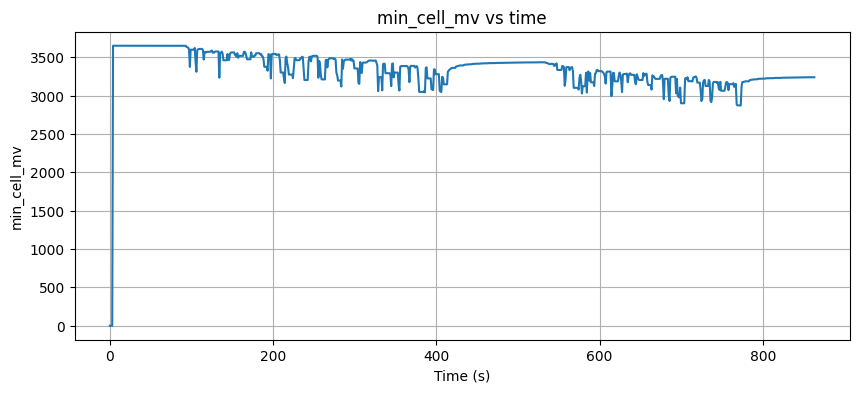

In [6]:
variable = "min_cell_mv"
plt.figure(figsize=(10, 4))
plt.plot(df_slow["time_s"], df_slow[variable])
plt.xlabel("Time (s)")
plt.ylabel(variable)
plt.title(f"{variable} vs time")
plt.grid(True)
plt.show()

In [7]:
df_slow["cell_spread_mv"] = (df_slow["max_cell_mv"] - df_slow["min_cell_mv"])
df_slow[['t_ms', 'min_cell_mv', 'max_cell_mv', 'avg_cell_mv', 'cell_spread_mv']].tail()

,t_ms,min_cell_mv,max_cell_mv,avg_cell_mv,cell_spread_mv
857,862257,3238,3399,3389,161
858,863257,3238,3399,3389,161
859,864257,3238,3399,3389,161
860,865257,3238,3399,3389,161
861,866257,3238,3399,3389,161


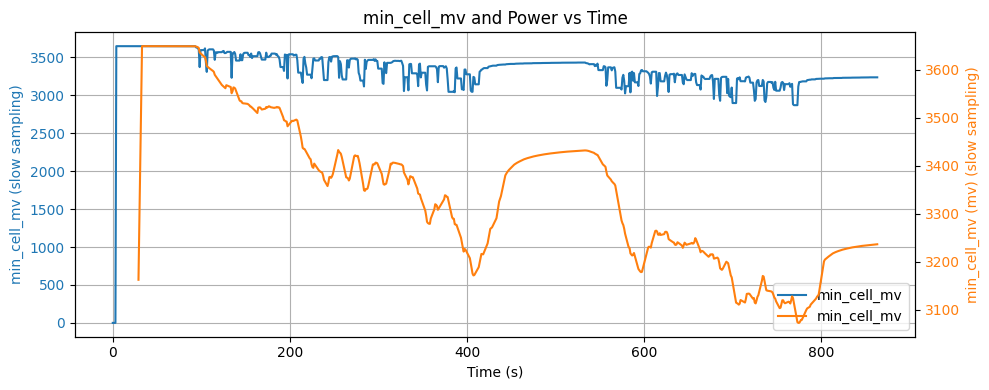

In [8]:
variable = "min_cell_mv"

# Create figure and primary axis
fig, ax1 = plt.subplots(figsize=(10, 4))

# Plot cell_spread_mv on left axis (blue)
color1 = 'tab:blue'
ax1.set_xlabel("Time (s)")
ax1.set_ylabel(f"{variable} (slow sampling)", color=color1)
line1 = ax1.plot(df_slow["time_s"], df_slow[variable], color=color1, label=variable)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True)

# Create secondary axis for power
ax2 = ax1.twinx()

# Plot power_kw on right axis (orange)
color2 = 'tab:orange'
ax2.set_ylabel("min_cell_mv (mv) (slow sampling)", color=color2)
line2 = ax2.plot(df_slow["time_s"], df_slow["min_cell_mv"].rolling(window=30).mean(), color=color2, label="min_cell_mv")
ax2.tick_params(axis='y', labelcolor=color2)

# Add title and combined legend
plt.title(f"{variable} and Power vs Time")
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='best')

plt.tight_layout()
plt.show()

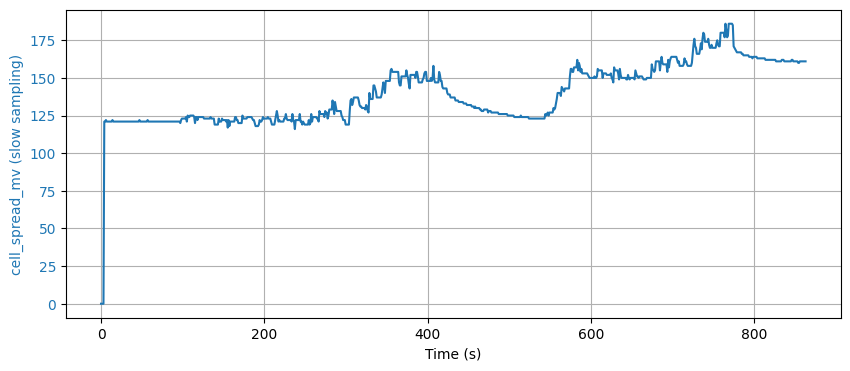

In [9]:
variable = "cell_spread_mv"

# Create figure and primary axis
fig, ax1 = plt.subplots(figsize=(10, 4))

# Plot cell_spread_mv on left axis (blue)
color1 = 'tab:blue'
ax1.set_xlabel("Time (s)")
ax1.set_ylabel(f"{variable} (slow sampling)", color=color1)
line1 = ax1.plot(df_slow["time_s"], df_slow[variable], color=color1, label=variable)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True)

In [10]:
largest_spreads = df_slow.nlargest(10, 'cell_spread_mv')[['t_ms', 'min_cell_mv', 'max_cell_mv', 'avg_cell_mv', 'cell_spread_mv']]
largest_spreads

,t_ms,min_cell_mv,max_cell_mv,avg_cell_mv,cell_spread_mv
763,768138,3113,3299,3280,186
767,772148,2871,3057,3037,186
768,773148,2871,3057,3037,186
769,774148,2871,3057,3037,186
770,775148,2871,3057,3037,186
771,776148,2871,3057,3037,186
772,777150,3117,3302,3283,185
764,769138,3140,3322,3304,182
736,741044,2980,3160,3142,180
757,762124,3148,3328,3311,180


In [11]:
all_rows = []
for t_ms in largest_spreads['t_ms']:
    closest_idx = (df_medium['t_ms'] - t_ms).abs().idxmin()
    closest_row =  df_medium.iloc[[closest_idx]]
    all_rows.append(closest_row)
merged_df = pd.concat(all_rows, ignore_index=True)
merged_df

,t_ms,apps1_pct,apps2_pct,pedal_pct,desired_torque_nm,power_kw,speed_mph,glv_voltage_v,inverter_temp_c,motor_temp_c,soc_pct,battery_temp_c,bms_flags_hex,bms_fault_code,imd_warn_alarms_hex,pm100_post_faults_hex,pm100_run_faults_hex,fan_duty_pct,rtd_state,time_s
0,768125,8.6,3.0,0.0,0.0,0.9,36,11.79,49.6,60.3,30,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,764.831
1,772195,7.8,4.7,0.0,0.0,0.3,29,11.78,50.9,61.1,29,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,768.901
2,773112,3.8,3.2,0.0,0.0,0.0,11,11.77,48.8,61.0,29,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,769.818
3,774133,16.5,13.5,8.6,14.7,1.1,10,11.71,46.3,60.9,29,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,770.839
4,775136,13.4,10.3,5.3,8.9,0.7,10,12.05,45.7,61.0,29,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,771.842
5,776145,9.7,7.3,1.6,2.7,0.4,10,11.67,45.3,61.0,29,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,772.851
6,777165,9.7,8.1,2.0,3.4,0.2,6,11.68,45.3,60.9,29,43,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,773.871
7,769148,9.6,0.7,0.0,0.0,0.0,18,11.78,47.3,60.6,30,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,765.854
8,741024,7.6,3.1,0.0,0.0,0.1,36,11.84,48.1,59.0,31,41,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,737.730
9,762128,9.0,3.5,0.0,0.0,0.0,34,11.81,48.6,60.6,30,42,0x02,0,0x0000,0x00000000,0x00000000,100,READY_TO_DRIVE,758.834


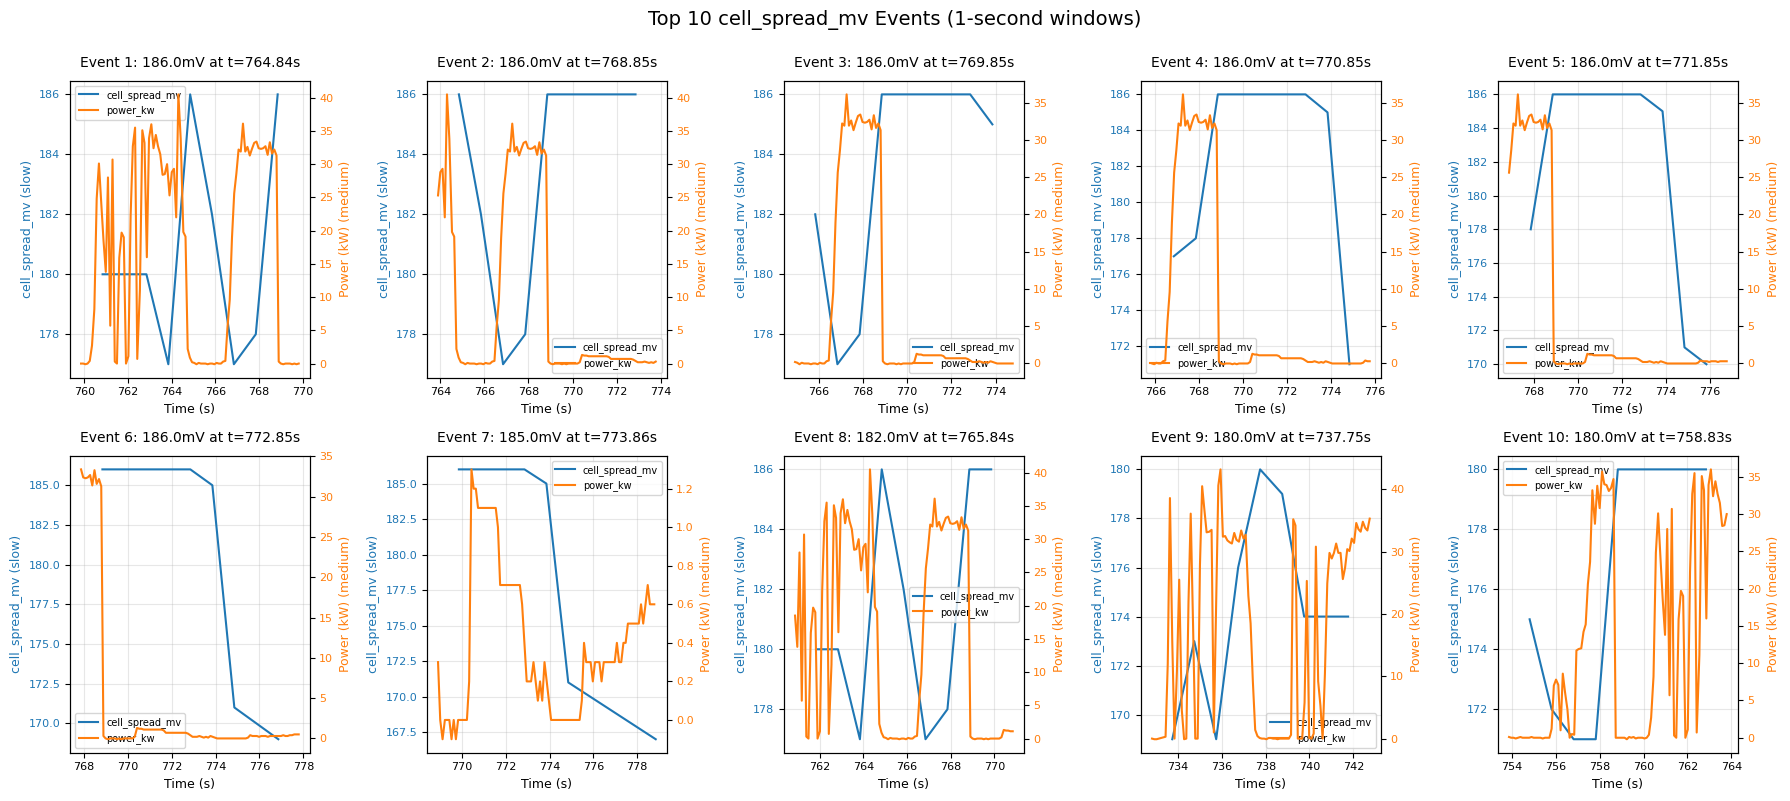

In [12]:
# Configuration
variable = "cell_spread_mv"
window_size = 10.0  # seconds

# Find top 10 cell_spread_mv events
# Get the top 10 values and their corresponding times
top_10_events = df_slow.nlargest(10, variable)[["time_s", variable]]
top_10_times = top_10_events["time_s"].values
top_10_values = top_10_events[variable].values

# Create 2x5 grid of subplots
fig, axes = plt.subplots(2, 5, figsize=(18, 8), sharex=False, sharey=False)
axes = axes.flatten()  # Flatten to easily iterate

# Plot each event
for i, (event_time, event_value) in enumerate(zip(top_10_times, top_10_values)):
    ax1 = axes[i]
    
    # Define 1-second window around the event
    time_start = event_time - window_size / 2
    time_end = event_time + window_size / 2
    
    # Filter dataframes for this time window
    df_slow_win = df_slow[(df_slow["time_s"] >= time_start) & (df_slow["time_s"] <= time_end)]
    df_medium_win = df_medium[(df_medium["time_s"] >= time_start) & (df_medium["time_s"] <= time_end)]
    
    # Check for empty data
    if df_slow_win.empty or df_medium_win.empty:
        ax1.text(0.5, 0.5, 'No data in window', ha='center', va='center', 
                 transform=ax1.transAxes, fontsize=10)
        ax1.set_title(f"Event {i+1}: No data", fontsize=10, color='red')
        continue
    
    # Plot cell_spread_mv on primary axis
    color1 = 'tab:blue'
    ax1.set_xlabel("Time (s)", fontsize=9)
    ax1.set_ylabel(f"{variable} (slow)", color=color1, fontsize=9)
    line1 = ax1.plot(df_slow_win["time_s"], df_slow_win[variable], 
                     color=color1, label=variable, linewidth=1.5)
    ax1.tick_params(axis='y', labelcolor=color1, labelsize=8)
    ax1.tick_params(axis='x', labelsize=8)
    ax1.grid(True, alpha=0.3)
    
    # Plot power_kw on secondary axis
    ax2 = ax1.twinx()
    color2 = 'tab:orange'
    ax2.set_ylabel("Power (kW) (medium)", color=color2, fontsize=9)
    line2 = ax2.plot(df_medium_win["time_s"], df_medium_win["power_kw"], 
                     color=color2, label="power_kw", linewidth=1.5)
    ax2.tick_params(axis='y', labelcolor=color2, labelsize=8)
    
    # Add title and legend
    ax1.set_title(f"Event {i+1}: {event_value:.1f}mV at t={event_time:.2f}s", 
                  fontsize=10, pad=10)
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='best', fontsize=7)

# Add a main title
fig.suptitle(f"Top 10 {variable} Events (1-second windows)", 
             fontsize=14, y=0.995)

# Adjust layout
plt.tight_layout()
plt.show()